### EDA – Tela 1 (simulação do INCT SiMAI)

Análise exploratória dos dados do INCT **depois da limpeza** (`scripts/limpeza_dados.ipynb`).
Os números são **estimativas de uma simulação**, não previsões nem contagens oficiais.

**Entrada:** `dados/processados/data.json` (uma linha por nível × bairro). Rodar o notebook de limpeza antes.
**Colunas principais:** `nivel_m`, `bairro`, `affected_buildings`, `total_buildings`, `percentage`, `population`, `affected_population`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
AZUL, CINZA, DESTAQUE = "#2F5D8A", "#8A8F98", "#C98B2B"   # cores sóbrias, sem vermelho alarmista

df = pd.read_json("../dados/processados/data_alterado.json")
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(6674, 11)


,nivel_m,bairro,affected_buildings,total_buildings,percentage,population,affected_population,flag,affected_buildings_orig,percentage_orig,affected_population_orig
0,3.0,Aberta dos Morros,0,4696,0.00,9854,0,,0,0,0
1,3.0,Agronomia,0,1771,0.00,2677,0,,0,0,0
2,3.0,Anchieta,28,589,4.75,791,38,,28,5,40
3,3.0,Arquipélago,4685,4688,99.94,6411,6407,,4685,100,6411
4,3.0,Auxiliadora,0,1995,0.00,8909,0,,0,0,0


### Visão geral dos dados

In [3]:
print("Níveis:", df.nivel_m.min(), "a", df.nivel_m.max(), "|", df.nivel_m.nunique(), "níveis")
print("Bairros:", df.bairro.nunique())
print("Nulos:", int(df.isna().sum().sum()))

base = df[df.nivel_m == 3.0]
print(f"População total de Porto Alegre (Censo 2022): {base.population.sum():,}".replace(",", "."))
print(f"Prédios totais (OpenStreetMap): {base.total_buildings.sum():,}".replace(",", "."))

Níveis: 3.0 a 10.0 | 71 níveis
Bairros: 94
Nulos: 0
População total de Porto Alegre (Censo 2022): 1.332.845
Prédios totais (OpenStreetMap): 486.389


### Gráfico 1 – População afetada na cidade por nível do rio

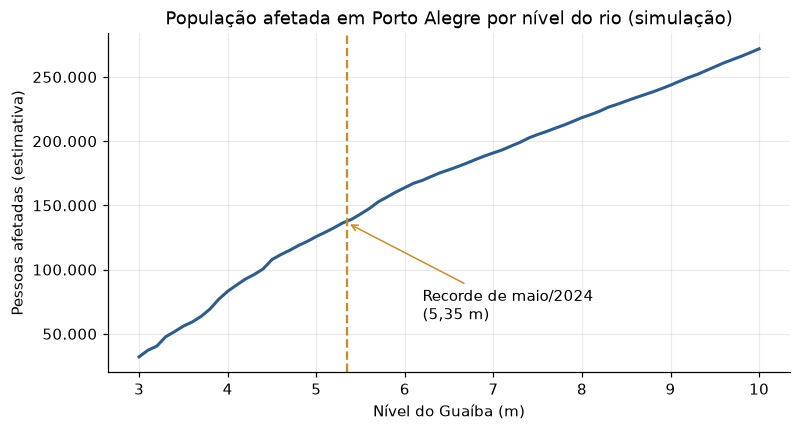

 3.0 m:   32.082 pessoas (2.4% da população) | 14.627 prédios | 23 bairros
 5.3 m:  136.389 pessoas (10.2% da população) | 53.989 prédios | 36 bairros
 8.0 m:  218.360 pessoas (16.4% da população) | 83.017 prédios | 49 bairros
10.0 m:  271.886 pessoas (20.4% da população) | 101.219 prédios | 54 bairros


In [4]:
cidade = df.groupby("nivel_m").agg(pessoas=("affected_population", "sum"),
                                   predios=("affected_buildings", "sum"),
                                   bairros=("affected_buildings", lambda s: (s > 0).sum()))
pop_total = df[df.nivel_m == 3.0].population.sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cidade.index, cidade.pessoas, color=AZUL, lw=2)
ax.axvline(5.35, color=DESTAQUE, ls="--")
ax.annotate("Recorde de maio/2024\n(5,35 m)", xy=(5.35, cidade.loc[5.3, "pessoas"]),
            xytext=(6.2, cidade.loc[5.3, "pessoas"] * 0.45), arrowprops=dict(arrowstyle="->", color=DESTAQUE))
ax.set(xlabel="Nível do Guaíba (m)", ylabel="Pessoas afetadas (estimativa)",
       title="População afetada em Porto Alegre por nível do rio (simulação)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
plt.show()

for n in [3.0, 5.3, 8.0, 10.0]:
    p = cidade.loc[n, "pessoas"]
    print(f"{n:>4} m: {p:>8,.0f} pessoas ({p / pop_total:.1%} da população) | {cidade.loc[n, 'predios']:,.0f} prédios | {cidade.loc[n, 'bairros']} bairros".replace(",", "."))

**Comentário.** A curva sobe de forma contínua, sem degraus, o que mostra que a limpeza removeu as quedas impossíveis. A 3,0 m, a simulação já indica ~32 mil pessoas afetadas, e a 5,3 m (nível do recorde de 2024, 5,35 m, que não está na grade de 0,1 m) cerca de 136 mil, aproximadamente 10% da população da cidade. O crescimento é mais rápido entre 3 e 5 m e depois desacelera, porque os bairros baixos são atingidos primeiro e depois sobram só os mais altos. Não há valor de 5,35 m; usamos 5,3 e 5,4 como vizinhos.

### Gráfico 2 – Quantos bairros são atingidos a cada nível

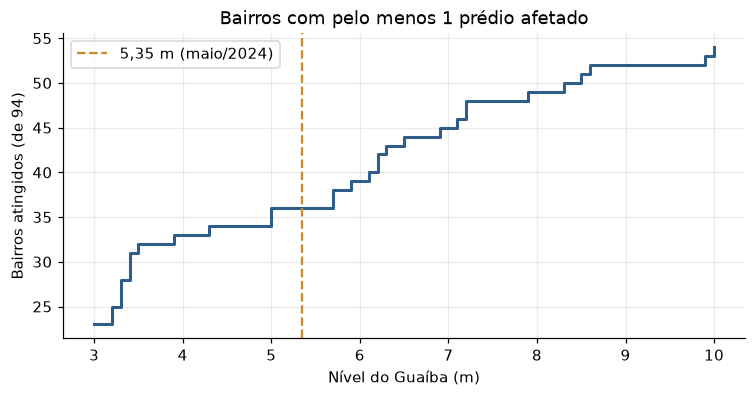

Bairros nunca atingidos até 10 m: 40


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.step(cidade.index, cidade.bairros, where="post", color=AZUL, lw=2)
ax.axvline(5.35, color=DESTAQUE, ls="--", label="5,35 m (maio/2024)")
ax.set(xlabel="Nível do Guaíba (m)", ylabel="Bairros atingidos (de 94)",
       title="Bairros com pelo menos 1 prédio afetado")
ax.legend()
plt.show()
print("Bairros nunca atingidos até 10 m:", 94 - int(cidade.bairros.max()))

**Comentário.** Já a 3,0 m, 23 bairros têm algum prédio afetado; a 5,3 m são 36, e a 10 m, 54. Isso significa que 40 dos 94 bairros nunca são atingidos, nem no cenário máximo. O número de bairros cresce pouco entre 5 e 6 m e mais depois, sinal de que há um grupo grande de bairros que só são atingidos em níveis bem acima do recorde de 2024.

### Gráfico 3 – % de prédios afetados por bairro (nível 5,3 m)

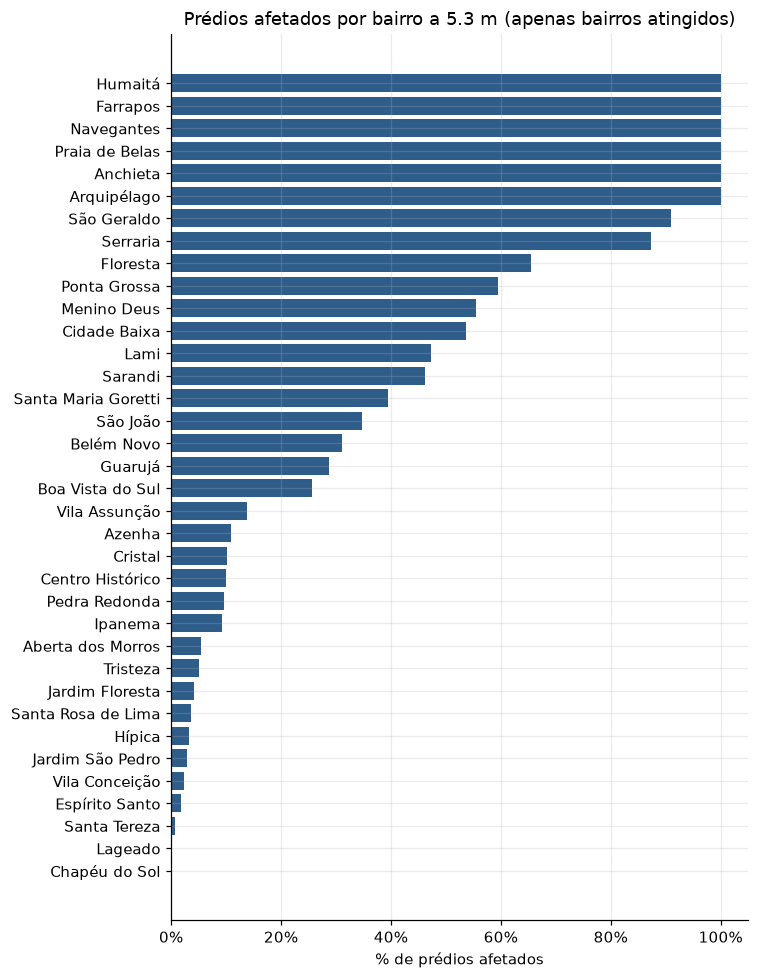

36 bairros atingidos; 12 com 50% ou mais dos prédios afetados


In [6]:
NIVEL = 5.3
x = df[(df.nivel_m == NIVEL) & (df.affected_buildings > 0)].sort_values("percentage")

fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(x.bairro, x.percentage, color=AZUL)
ax.set(xlabel="% de prédios afetados", title=f"Prédios afetados por bairro a {NIVEL} m (apenas bairros atingidos)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()
print(len(x), "bairros atingidos;", int((x.percentage >= 50).sum()), "com 50% ou mais dos prédios afetados")

**Comentário.** A 5,3 m, 36 bairros são atingidos, e 12 deles têm metade ou mais dos prédios afetados. Seis bairros aparecem com 100% (Arquipélago, Anchieta, Farrapos, Praia de Belas, Navegantes e Humaitá). A distribuição é muito desigual: alguns bairros têm quase todos os prédios afetados, enquanto muitos outros têm menos de 10%. Por isso o gráfico por bairro é mais informativo que só o total da cidade.

### Gráfico 4 – Ranking: bairros com mais pessoas afetadas (5,3 m)

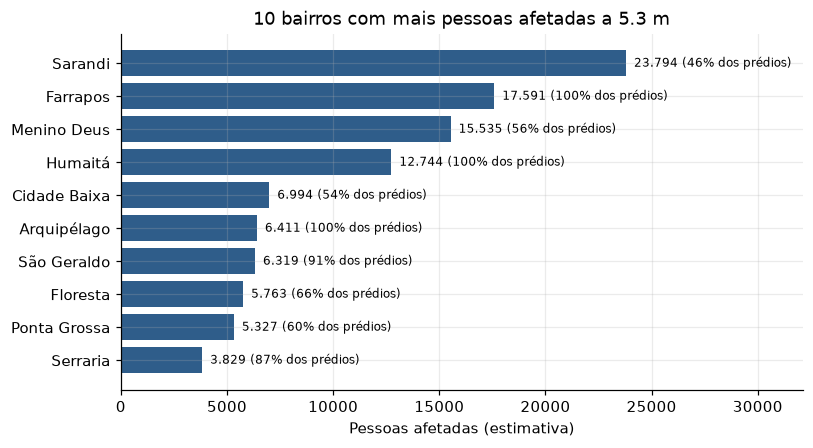

In [7]:
r = (df[df.nivel_m == NIVEL].sort_values("affected_population", ascending=False).head(10)
       .sort_values("affected_population"))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(r.bairro, r.affected_population, color=AZUL)
for y, (p, pc) in enumerate(zip(r.affected_population, r.percentage)):
    ax.text(p, y, f"  {p:,.0f} ({pc:.0f}% dos prédios)".replace(",", "."), va="center", fontsize=8)
ax.set(xlabel="Pessoas afetadas (estimativa)", title=f"10 bairros com mais pessoas afetadas a {NIVEL} m")
ax.set_xlim(0, r.affected_population.max() * 1.35)
plt.show()

**Comentário.** O ranking por número de pessoas é diferente do ranking por porcentagem. Sarandi lidera em pessoas (~23,8 mil), mas só 46% dos prédios estão afetados; já Farrapos (~17,6 mil) e Humaitá (~12,7 mil) têm 100%. Bairros grandes pesam mais no total absoluto. No dashboard, vale mostrar os dois critérios (pessoas e %) para não induzir uma leitura única.

### Gráfico 5 – Mapa de calor: bairro × nível

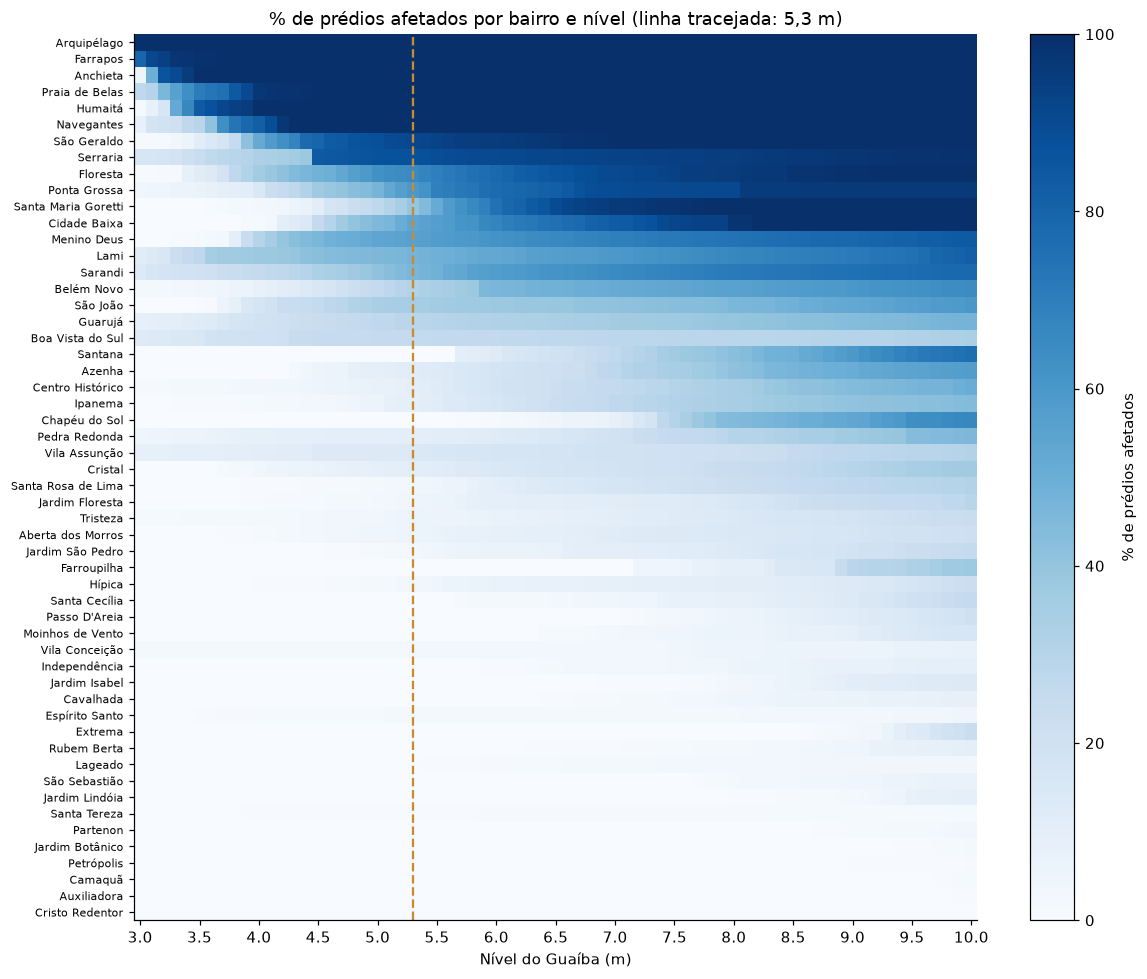

In [8]:
atingidos = df.groupby("bairro").affected_buildings.max()
atingidos = atingidos[atingidos > 0].index
h = (df[df.bairro.isin(atingidos)].pivot(index="bairro", columns="nivel_m", values="percentage"))
h = h.loc[h.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(h.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(h))); ax.set_yticklabels(h.index, fontsize=7)
ax.set_xticks(range(0, h.shape[1], 5)); ax.set_xticklabels([f"{c:.1f}" for c in h.columns[::5]])
ax.axvline(list(h.columns).index(5.3), color=DESTAQUE, ls="--")
ax.set(xlabel="Nível do Guaíba (m)", title="% de prédios afetados por bairro e nível (linha tracejada: 5,3 m)")
ax.grid(False)
fig.colorbar(im, label="% de prédios afetados")
plt.tight_layout(); plt.show()

**Comentário.** No mapa de calor, os bairros no topo já têm porcentagem alta desde níveis baixos, os do meio vão enchendo gradualmente e os de baixo só são atingidos em níveis altos ou ficam com porcentagem baixa mesmo a 10 m. Degraus verticais bruscos em alguns bairros (por exemplo Serraria em 4,5 m e Humaitá em 3,3 m) são saltos grandes que mantivemos no dado limpo porque são monotônicos e podem ser reais; vale destacá-los no relatório como ponto de atenção.

### Gráfico 6 – Tamanho dos bairros e hipótese da população

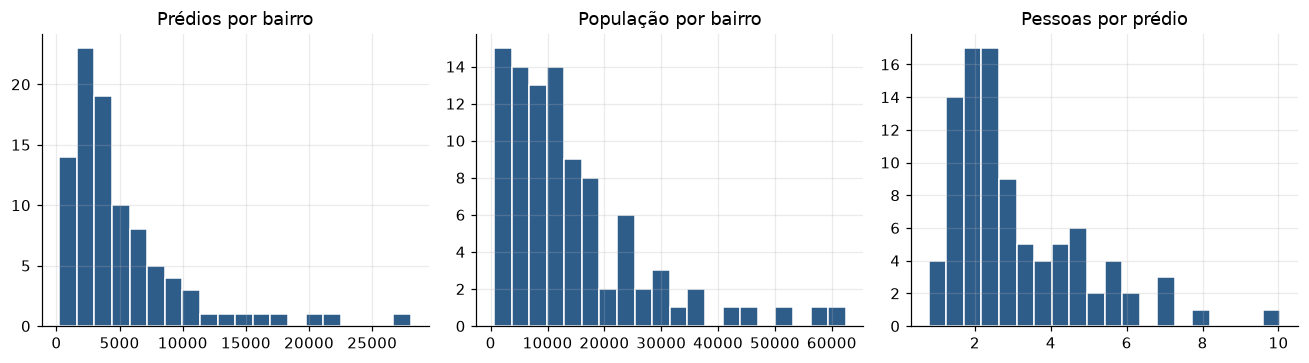

count    94.00
mean      3.09
std       1.75
min       0.78
25%       1.98
50%       2.42
75%       4.11
max      10.05
Name: pessoas_por_predio, dtype: float64
           bairro  pessoas_por_predio
79    São Caetano            0.779787
26        Extrema            1.003828
11        Bom Fim            7.845560
39  Jardim Europa           10.050575


In [9]:
b = df[df.nivel_m == 3.0].assign(pessoas_por_predio=lambda x: x.population / x.total_buildings)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, col, t in zip(ax, ["total_buildings", "population", "pessoas_por_predio"],
                     ["Prédios por bairro", "População por bairro", "Pessoas por prédio"]):
    a.hist(b[col], bins=20, color=AZUL, edgecolor="white"); a.set(title=t)
plt.tight_layout(); plt.show()
print(b.pessoas_por_predio.describe().round(2))
print(b.sort_values("pessoas_por_predio")[["bairro", "pessoas_por_predio"]].iloc[[0, 1, -2, -1]])

**Comentário.** Os bairros são muito diferentes em tamanho: poucos concentram muitos prédios e pessoas, e a maioria é pequena. A razão pessoas por prédio tem mediana de ~2,4 e varia de cerca de 0,8 (São Caetano) a 10 (Jardim Europa). Como a população afetada supõe pessoas distribuídas igualmente entre todos os prédios, o resultado fica subestimado em bairros de prédios altos e residenciais (como o Centro Histórico, ~7 pessoas por prédio, a mesma faixa de Bom Fim e Bela Vista) e superestimado em bairros com muitos prédios não residenciais. Essa limitação deve aparecer no aviso da Tela 1.

### Gráfico 7 – Efeito da limpeza (antes × depois)

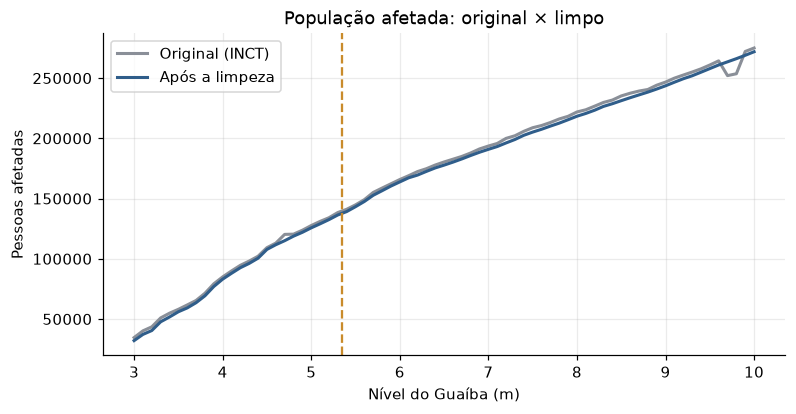

nivel_m
3.0     2523
5.3     2025
10.0    3107
dtype: int64


In [10]:
import json
raw = json.load(open("../dados/originais/data.json", encoding="utf-8"))
orig = pd.DataFrame([{"nivel_m": float(n.removesuffix("m").replace("_", ".")), "bairro": b, **v}
                     for n, bs in raw.items() for b, v in bs.items()])
c0 = orig.groupby("nivel_m").affected_population.sum()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(c0.index, c0, color=CINZA, lw=2, label="Original (INCT)")
ax.plot(cidade.index, cidade.pessoas, color=AZUL, lw=2, label="Após a limpeza")
ax.axvline(5.35, color=DESTAQUE, ls="--")
ax.set(xlabel="Nível do Guaíba (m)", ylabel="Pessoas afetadas", title="População afetada: original × limpo")
ax.legend(); plt.show()
print((c0 - cidade.pessoas).loc[[3.0, 5.3, 10.0]].round(0))

**Comentário.** A diferença entre as duas curvas vem principalmente do arredondamento para cima do percentual no arquivo original: o original superestima a população afetada em 2 a 3 mil pessoas (cerca de 2.500 a 3,0 m, 2.000 a 5,3 m e 3.100 a 10 m). O ajuste é pequeno em relação à população total, mas é sistemático, e muda o ranking de bairros pequenos (por exemplo, 1 prédio afetado em Santa Tereza virava 314 pessoas).